Explore2 notebook explore the 14-17 April 2023 sample, which covers the period before, during and after the nuclear exit, to check null values.

In [59]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns

In [60]:
with open("/Users/emrekaya/germany_grid_carbon_forecast/data/raw/sample_public_power_2023-04-14_17.json") as f:
    data = json.load(f)


In [61]:
data.keys()

dict_keys(['unix_seconds', 'production_types', 'deprecated'])

In [62]:
len(data["unix_seconds"]) 

384

In [63]:
print(data["unix_seconds"][0])
print(data["unix_seconds"][1])
# same problem in here , I ll fix time zone because i need hourly not like 15 min period , 
# difference between first and second index is 900 seconds.
# it means 15 min.

1681423200
1681424100


In [64]:
len(data["production_types"])

22

In [65]:
data["production_types"][0].keys()

dict_keys(['name', 'data'])

In [66]:
# production types 
cols = {}

for source in data["production_types"]:
    print(source["name"])
    
    cols[source["name"]] = source["data"]
# I ll use production columns because formul need production columns.
# 16 columns are production.

Hydro pumped storage consumption
Cross border electricity trading
Nuclear
Hydro Run-of-River
Biomass
Fossil brown coal / lignite
Fossil hard coal
Fossil oil
Fossil coal-derived gas
Fossil gas
Geothermal
Hydro water reservoir
Hydro pumped storage
Others
Waste
Wind offshore
Wind onshore
Solar
Load
Residual load
Renewable share of load
Renewable share of generation


In [67]:
df = pd.DataFrame(cols)

In [68]:
df.head()

,Hydro pumped storage consumption,Cross border electricity trading,Nuclear,Hydro Run-of-River,Biomass,Fossil brown coal / lignite,Fossil hard coal,Fossil oil,Fossil coal-derived gas,Fossil gas,...,Hydro pumped storage,Others,Waste,Wind offshore,Wind onshore,Solar,Load,Residual load,Renewable share of load,Renewable share of generation
0,-520.8,2103.9,2623.0,1805.2,4299.4,11791.0,5289.9,361.5,655.0,5820.2,...,845.8,233.9,977.8,5174.6,2351.3,0.0,46487.6,38961.7,30.4,34.1
1,-455.2,2115.0,2620.1,1820.6,4278.4,11812.9,5091.7,361.5,519.6,5368.4,...,672.6,233.9,980.3,5698.6,2405.5,0.0,45727.3,37623.2,32.2,35.7
2,-475.2,2099.3,2621.0,1841.4,4269.6,11815.7,5060.2,361.5,519.6,5148.8,...,246.8,233.9,981.0,5398.6,2467.1,0.0,44988.4,37122.7,32.2,35.6
3,-536.8,2081.0,2622.0,1848.3,4263.2,11815.5,4895.7,361.5,516.2,4990.8,...,182.7,234.0,973.8,5074.3,2534.0,0.0,44612.2,37003.9,31.9,35.4
4,-888.1,2753.4,2621.0,1858.6,4234.3,11792.8,4784.4,362.4,521.0,4974.3,...,308.3,234.0,979.1,4826.5,2664.8,0.0,44351.1,36859.8,31.8,35.3


In [69]:
df.index = pd.to_datetime(data["unix_seconds"], unit="s", utc=True)

In [70]:
df.isna().sum()
# nuclear has 192 null values.

Hydro pumped storage consumption      0
Cross border electricity trading      0
Nuclear                             192
Hydro Run-of-River                    0
Biomass                               0
Fossil brown coal / lignite           0
Fossil hard coal                      0
Fossil oil                            0
Fossil coal-derived gas               0
Fossil gas                            0
Geothermal                            0
Hydro water reservoir                 0
Hydro pumped storage                  0
Others                                0
Waste                                 0
Wind offshore                         0
Wind onshore                          0
Solar                                 0
Load                                  0
Residual load                         0
Renewable share of load               0
Renewable share of generation         0
dtype: int64

In [71]:
df["Nuclear"][df["Nuclear"].isna()]
# days which one has null values
# first NaN value is in 15 April 22:00 , summer time +2 and it means = 16 April 00:00

2023-04-15 22:00:00+00:00   NaN
2023-04-15 22:15:00+00:00   NaN
2023-04-15 22:30:00+00:00   NaN
2023-04-15 22:45:00+00:00   NaN
2023-04-15 23:00:00+00:00   NaN
                             ..
2023-04-17 20:45:00+00:00   NaN
2023-04-17 21:00:00+00:00   NaN
2023-04-17 21:15:00+00:00   NaN
2023-04-17 21:30:00+00:00   NaN
2023-04-17 21:45:00+00:00   NaN
Name: Nuclear, Length: 192, dtype: float64

In [72]:
df["Nuclear"].dropna().index[-1] 
# last usage in 15 April 21:45 + 2 = 23:45

Timestamp('2023-04-15 21:45:00+0000', tz='UTC')

In [73]:
print(df["Nuclear"].dropna().iloc[-1])
print(df["Nuclear"].dropna().iloc[-2])
print(df["Nuclear"].dropna().iloc[-3])
print(df["Nuclear"].dropna().iloc[-4])
# We can see they decreased Nuclear usage step by step and last value is 50.6

50.6
114.9
347.0
571.1


In [74]:
# generate columns 16
generate_columns = [
    "Nuclear",
    "Hydro Run-of-River",
    "Biomass",
    "Fossil brown coal / lignite",
    "Fossil hard coal",
    "Fossil oil",
    "Fossil coal-derived gas",
    "Fossil gas",
    "Geothermal",
    "Hydro water reservoir",
    "Hydro pumped storage",
    "Others",
    "Waste",
    "Wind offshore",
    "Wind onshore",
    "Solar",
]

In [75]:
gen_col = df[generate_columns]

In [76]:
gen_col.shape

(384, 16)

In [ ]:
gen_col.head()
# I ll fix time, 15 min period to hourly for open meteo.

,Nuclear,Hydro Run-of-River,Biomass,Fossil brown coal / lignite,Fossil hard coal,Fossil oil,Fossil coal-derived gas,Fossil gas,Geothermal,Hydro water reservoir,Hydro pumped storage,Others,Waste,Wind offshore,Wind onshore,Solar
2023-04-13 22:00:00+00:00,2623.0,1805.2,4299.4,11791.0,5289.9,361.5,655.0,5820.2,16.4,45.5,845.8,233.9,977.8,5174.6,2351.3,0.0
2023-04-13 22:15:00+00:00,2620.1,1820.6,4278.4,11812.9,5091.7,361.5,519.6,5368.4,16.4,43.8,672.6,233.9,980.3,5698.6,2405.5,0.0
2023-04-13 22:30:00+00:00,2621.0,1841.4,4269.6,11815.7,5060.2,361.5,519.6,5148.8,16.4,48.0,246.8,233.9,981.0,5398.6,2467.1,0.0
2023-04-13 22:45:00+00:00,2622.0,1848.3,4263.2,11815.5,4895.7,361.5,516.2,4990.8,16.4,46.9,182.7,234.0,973.8,5074.3,2534.0,0.0
2023-04-13 23:00:00+00:00,2621.0,1858.6,4234.3,11792.8,4784.4,362.4,521.0,4974.3,16.4,40.5,308.3,234.0,979.1,4826.5,2664.8,0.0


In [ ]:
gen_col.isna().sum()
# I am going to handle NaN values.

Nuclear                        192
Hydro Run-of-River               0
Biomass                          0
Fossil brown coal / lignite      0
Fossil hard coal                 0
Fossil oil                       0
Fossil coal-derived gas          0
Fossil gas                       0
Geothermal                       0
Hydro water reservoir            0
Hydro pumped storage             0
Others                           0
Waste                            0
Wind offshore                    0
Wind onshore                     0
Solar                            0
dtype: int64

In [81]:
# Handling null values
gen_col["Nuclear"] = gen_col["Nuclear"].fillna(0)

In [82]:
gen_col.isna().sum()

Nuclear                        0
Hydro Run-of-River             0
Biomass                        0
Fossil brown coal / lignite    0
Fossil hard coal               0
Fossil oil                     0
Fossil coal-derived gas        0
Fossil gas                     0
Geothermal                     0
Hydro water reservoir          0
Hydro pumped storage           0
Others                         0
Waste                          0
Wind offshore                  0
Wind onshore                   0
Solar                          0
dtype: int64

In [ ]:
# 15 min to hourly fixing

In [83]:
gen_hourly = gen_col.resample("1h").mean()

In [ ]:
print(gen_hourly.shape)
print(gen_col.shape)
# 384 / 4 = 96

(96, 16)
(384, 16)


In [ ]:
gen_hourly.head()
# time changed.(15 min preiod to hourly)

,Nuclear,Hydro Run-of-River,Biomass,Fossil brown coal / lignite,Fossil hard coal,Fossil oil,Fossil coal-derived gas,Fossil gas,Geothermal,Hydro water reservoir,Hydro pumped storage,Others,Waste,Wind offshore,Wind onshore,Solar
2023-04-13 22:00:00+00:00,2621.525,1828.875,4277.650,11808.775,5084.375,361.500,552.600,5332.050,16.4,46.050,486.975,233.925,978.225,5336.525,2439.475,0.000
2023-04-13 23:00:00+00:00,2621.600,1871.025,4237.100,11792.625,4714.150,361.975,519.875,4925.350,16.5,39.550,153.800,235.600,973.725,4609.400,2824.975,0.000
2023-04-14 00:00:00+00:00,2623.300,1878.850,4219.325,11665.400,4464.075,361.500,522.350,4706.350,16.5,41.350,44.750,252.650,973.825,4024.150,3191.800,0.000
2023-04-14 01:00:00+00:00,2625.200,1877.525,4216.650,11619.600,4452.250,361.500,543.650,4739.800,16.5,46.875,163.375,252.600,972.175,2979.850,3276.750,0.000
2023-04-14 02:00:00+00:00,2623.450,1867.675,4262.350,11579.225,4577.725,361.675,535.375,4834.725,16.3,52.875,257.750,252.650,972.300,2447.600,3070.625,1.675


In [ ]:
#manuel control 
print(gen_col.iloc[32:36]["Solar"].mean()) # 8 * 4 = 32 and + 4 row for the quarters 00,15,30,45 it means 32,33,34,35
print(gen_hourly.iloc[8]["Solar"])

6175.25
6175.25


Emission Factors

In [94]:
# PLACEHOLDER values (gCO2/kWh), values are examples , real values will fill after with sources.
EF = {
    "Nuclear": 10,
    "Hydro Run-of-River": 10,
    "Biomass": 250,
    "Fossil brown coal / lignite": 1000,
    "Fossil hard coal": 1000,
    "Fossil oil": 700,
    "Fossil coal-derived gas": 700,
    "Fossil gas": 400,
    "Geothermal": 30,
    "Hydro water reservoir": 10,
    "Hydro pumped storage": 250,
    "Others": 250,
    "Waste": 250,
    "Wind offshore": 10,
    "Wind onshore": 10,
    "Solar": 50,
}
print(set(EF) == set(gen_col)) # match checked

True


In [95]:
ef = pd.Series(EF)

In [97]:
ef.head

<bound method NDFrame.head of Nuclear                          10
Hydro Run-of-River               10
Biomass                         250
Fossil brown coal / lignite    1000
Fossil hard coal               1000
Fossil oil                      700
Fossil coal-derived gas         700
Fossil gas                      400
Geothermal                       30
Hydro water reservoir            10
Hydro pumped storage            250
Others                          250
Waste                           250
Wind offshore                    10
Wind onshore                     10
Solar                            50
dtype: int64>

compute carbon intensity
for example: when there is high level wind and sun, CI low(cleaner)
carbon intensity is target variable of the project.

In [98]:
def compute_ci(gen_hourly, ef):
    numerator = (gen_hourly * ef).sum(axis=1)
    denominator = gen_hourly.sum(axis=1)
    return numerator/denominator

In [99]:
# testing
test_ci = compute_ci(gen_hourly, ef)
print(test_ci.shape)

(96,)


In [100]:
print(test_ci.describe())

count     96.000000
mean     433.867922
std       82.492085
min      246.262671
25%      381.189862
50%      444.074916
75%      494.716655
max      581.808048
dtype: float64


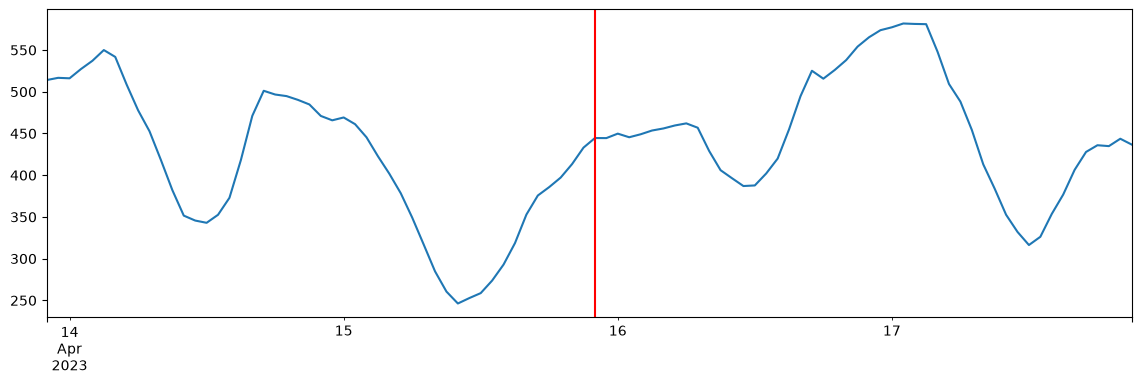

In [ ]:
test_ci.plot(figsize=(14, 4))
plt.axvline(pd.Timestamp("2023-04-15 22:00", tz="UTC"), color="red")
# right side (16-17 april) is after nuclear exit
# red line is first null in Nuclear 

Findings

Data :
- 14 - 17 April has 384 time stamps and 22 sources.

 Nulls : 
- Nuclear has 192 nulls in last 2 days 16 and 17 April , first null is when they exit the nuclear 15 APR 2023 22:00 UTC = 16 APR 2024(local) 

- Nuclear nulls are handled by set to 0 method.

- Last 4 values before nulls decreased step by step and last value is 51 MW.

Carbon Intensity:
- Hourly CI shape (96,)
- mean approx. 434 and range ≈ 246-582
- CI is lowest around midday and highest at night.
- Higher level after the exit consistent with fossil replacing nuclear(weekday and weather conditions are not separated.)

Notes:
- Placeholder values (gCO2/kWh), values are examples , real values will fill after with sources.